# The MESSAGE Energy Model on a Small Example: Westeros

**ENGG562/ENV462 · Climate Change Governance: Science, Data & Models · LUMS · Fall 2026**

**Module 3: Scenarios & Integrated Assessment** · Coding exercise 04 · Mini integrated assessment model series, notebook 2 of 5 · Requires coding exercise 03

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LUMS-WIT/climate-futures/blob/main/content-src/coding/04-message-westeros.ipynb)

This notebook introduces the structure that MESSAGEix gives to the same idea, using the teaching example of the official MESSAGEix tutorials: the fictional country of **Westeros**, which must electrify its homes. The example is deliberately tiny (one country, four technologies, three decades) so that every number in the result can be traced back to an input.

All code in this notebook uses the course module `miniiam`, a teaching-scale reimplementation of MESSAGEix written in Python. Its commands have the **same names and arguments** as the `message_ix` package (`Scenario`, `make_df`, `add_set`, `add_par`, `solve`, `var`), and the data are the same as in the official tutorial *westeros_baseline*. Code written here can therefore be run on the real MESSAGEix model with very few changes, which notebook 07 does.

| Notebook | Content |
|---|---|
| 03 | Linear optimisation, shadow prices, and a small capacity expansion model |
| **04 (this notebook)** | **Westeros: the MESSAGE formulation on a small example** |
| 05 | World: the same formulation applied to a global energy system |
| 06 | MESSAGE-MACRO: linking the energy model to a macro-economic growth model |
| 07 | From the mini model to the real `message_ix` package |

Prompts: **💬 Predict**, **✏️ Exercise** (replace every `...` or `___`; self-checks print ✅ or ❌), and **💬 Question**.

## Learning objectives

On completing this notebook, students should be able to:

1. Describe an energy system as a **reference energy system** of technologies that convert commodities between levels (secondary, final, useful).
2. Build a MESSAGE scenario from sets and parameters using the `message_ix` interface.
3. Read the main results (`ACT`, `CAP`, `CAP_NEW`, `PRICE_COMMODITY`) and explain them with reference to the input data.
4. Identify the equations of the MESSAGE formulation in the optimisation problem that the solver receives.
5. Introduce an emission bound and an emission tax, and explain why a cumulative bound produces a carbon price that rises at the interest rate.

## Structure of the notebook

| Part | Content | Approximate time |
|---|---|---|
| 0 | Setup | 5 min |
| 1 | The Westeros energy system | 10 min |
| 2 | Building the scenario, step by step | 35 min |
| 3 | Solving and reading the results | 20 min |
| 4 | What the solver sees: the MESSAGE equations | 15 min |
| 5 | Climate policy in Westeros: an emission bound | 15 min |
| 6 | Bounds, prices, and taxes | 15 min |
| 7 | Adding a technology | 15 min |
| 8 | From Westeros to the world | 5 min |

---
# Part 0 · Setup

The cell below installs Pyomo and the HiGHS solver and downloads the course module `miniiam.py` when the notebook runs in Colab. On a personal computer, place `miniiam.py` in the same folder as this notebook and install the packages once with `pip install pyomo highspy`.

In [1]:
import os
import sys

if "google.colab" in sys.modules:
    !pip install --quiet pyomo highspy
    !wget --quiet --timestamping https://raw.githubusercontent.com/LUMS-WIT/climate-futures/main/content-src/coding/miniiam.py
else:
    # Local run: miniiam.py sits next to the student copies, one folder above the trainer copies
    found = [d for d in (".", "..", "content-src/coding") if os.path.exists(os.path.join(d, "miniiam.py"))]
    if found:
        sys.path.insert(0, os.path.abspath(found[0]))
    else:
        print("miniiam.py not found from", os.getcwd(), "- place it next to this notebook.")

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

import miniiam as mi
from miniiam import make_df

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.precision", 2)

In [3]:
def check(description, condition):
    """Self-check helper: prints a tick or a cross. It never stops the notebook."""
    try:
        passed = bool(condition())
    except Exception:
        passed = False
    print(("✅ " if passed else "❌ ") + description)

---
# Part 1 · The Westeros energy system

Westeros wants to supply light to its population. Light is an **energy service** and Electricity is generated in power plants, transported over a grid, and converted into light by bulbs. In MESSAGE, each of these steps is a **technology**, and each technology converts an input **commodity** at one **level** into an output commodity at another level:

```
   SECONDARY level            FINAL level                 USEFUL level
  ┌──────────┐
  │ coal_ppl │──┐
  └──────────┘  │ electricity   ┌──────┐  electricity   ┌──────┐   light
                ├──────────────▶│ grid │───────────────▶│ bulb │──────────▶  demand
  ┌──────────┐  │               └──────┘  (90% passes)  └──────┘
  │ wind_ppl │──┘
  └──────────┘
```

This network is called the **reference energy system (RES)**. All MESSAGE model, from Westeros to the global MESSAGEix-GLOBIOM model used for the IPCC, is a reference energy system of this kind; the global model simply has thousands of technologies and many regions.

| MESSAGE concept | Westeros example |
|---|---|
| `commodity` | electricity, light |
| `level` | secondary (power plant output), final (delivered to homes), useful (the service) |
| `technology` | coal_ppl, wind_ppl, grid, bulb |
| `input` / `output` | the grid takes 1/0.9 units of secondary electricity per unit of final electricity |
| `demand` | light at the useful level |

---
# Part 2 · Building the scenario, step by step

A **scenario** is created and filled with data in a fixed order: the time horizon, the sets, then the parameters. The code below mirrors the official MESSAGEix tutorial.

## 2.1 Time horizon and sets

Westeros counts years from the founding of its kingdom. The model covers three ten-year periods, 700, 710, and 720, with one historical period (690) that describes the existing system. In MESSAGE, the label of a period is its **last** year: period 700 covers the years 691 to 700.

In [4]:
scenario = mi.Scenario(model="Westeros Electrified", scenario="baseline")

history = [690]
model_horizon = [700, 710, 720]
scenario.add_horizon(year=history + model_horizon, firstmodelyear=model_horizon[0])

country = "Westeros"
scenario.add_spatial_sets({"country": country})

scenario.add_set("commodity", ["electricity", "light"])
scenario.add_set("level", ["secondary", "final", "useful"])
scenario.add_set("technology", ["coal_ppl", "wind_ppl", "grid", "bulb"])
scenario.add_set("mode", "standard")

scenario.par("duration_period")

,year,value,unit
0,690,10,y
1,700,10,y
2,710,10,y
3,720,10,y


## 2.2 Demand

Demand for light grows with the economy. The tutorial assumes that each of the one million households uses 40 kWh of light per month in the first period, and that demand then grows in proportion to GDP, which is 1.5 times larger in 710 and 1.9 times larger in 720.

$$
\text{demand}_{700} = \frac{40 \text{ kWh} \times 12 \times 1{,}000{,}000}{8{,}760 \text{ h}} \approx 55 \text{ GW-years per year (GWa)}
$$

### ✏️ Exercise 1: The demand for light

Create the DataFrame `light_demand` with one row per model period, using `make_df("demand", ...)`. The value is `demand_per_year` multiplied by the GDP profile and rounded to whole numbers. Then add it to the scenario.

In [5]:
gdp_profile = pd.Series([1.0, 1.5, 1.9], index=model_horizon)
demand_per_year = 40 * 12 * 1000 / 8760

light_demand = make_df(
    "demand",
    node=country,
    commodity=___,
    level=___,
    year=model_horizon,
    time="year",
    value=(demand_per_year * gdp_profile).round().values,
    unit="GWa",
)
scenario.add_par("demand", light_demand)
light_demand

,node,commodity,level,year,time,value,unit
0,Westeros,,,700,year,55.0,GWa
1,Westeros,,,710,year,82.0,GWa
2,Westeros,,,720,year,104.0,GWa


In [6]:
check("demand is 55, 82 and 104 GWa", lambda: list(scenario.par("demand")["value"]) == [55, 82, 104])
check("demand is for light at the useful level",
      lambda: set(scenario.par("demand")["commodity"]) == {"light"} and set(scenario.par("demand")["level"]) == {"useful"})

✅ demand is 55, 82 and 104 GWa
❌ demand is for light at the useful level


## 2.3 Technical lifetime

The lifetime determines for how many periods a unit of new capacity remains available. It is defined for each **vintage** (the period in which capacity is built).

In [7]:
lifetime = {"coal_ppl": 20, "wind_ppl": 20, "bulb": 1, "grid": 30}

for tec, val in lifetime.items():
    df = make_df("technical_lifetime", node_loc=country, year_vtg=history + model_horizon,
                 unit="y", technology=tec, value=val)
    scenario.add_par("technical_lifetime", df)

scenario.par("technical_lifetime").head()

,node_loc,technology,year_vtg,value,unit
0,Westeros,coal_ppl,690,20,y
1,Westeros,coal_ppl,700,20,y
2,Westeros,coal_ppl,710,20,y
3,Westeros,coal_ppl,720,20,y
4,Westeros,wind_ppl,690,20,y


## 2.4 Inputs and outputs: the reference energy system in numbers

Parameters that describe operation are indexed by both the **vintage year** `year_vtg` and the **active year** `year_act`, because a plant built in 690 may still run in 700. The method `vintage_and_active_years()` lists every valid pair given the lifetime.

In [8]:
year_df = scenario.vintage_and_active_years((country, "coal_ppl"), in_horizon=False)
year_df

,year_vtg,year_act
0,690,690
1,690,700
2,700,700
3,700,710
4,710,710
5,710,720
6,720,720


**💬 Predict before running the next cell.** A coal plant built in 690 has a lifetime of 20 years. In which periods can it operate?

*Answer:* *(write the answer here)*

In [12]:
# The bulb converts one unit of final electricity into one unit of light
year_df = scenario.vintage_and_active_years((country, "bulb"), in_horizon=False)
base = dict(node_loc=country, year_vtg=year_df["year_vtg"], year_act=year_df["year_act"],
            technology="bulb", mode="standard", time="year", unit="-")

bulb_out = make_df("output", **base, node_dest=country, time_dest="year",
                   commodity="light", level="useful", value=1.0)
bulb_in = make_df("input", **base, node_origin=country, time_origin="year",
                  commodity="electricity", level="final", value=1.0)
scenario.add_par("output", bulb_out)
scenario.add_par("input", bulb_in)
bulb_in.head(3)

,node_loc,technology,year_vtg,year_act,mode,node_origin,commodity,level,time,time_origin,value,unit
0,Westeros,bulb,690,690,standard,Westeros,electricity,final,year,year,1.0,-
1,Westeros,bulb,700,700,standard,Westeros,electricity,final,year,year,1.0,-
2,Westeros,bulb,710,710,standard,Westeros,electricity,final,year,year,1.0,-


### ✏️ Exercise 2: The grid

The grid delivers one unit of **final** electricity for every 1/0.9 units of **secondary** electricity it takes in (10% is lost in transmission). Add its `output` and `input` in the same way as for the bulb.

In [15]:
grid_efficiency = 0.9
year_df = scenario.vintage_and_active_years((country, "grid"), in_horizon=False)
base = dict(node_loc=country, year_vtg=year_df["year_vtg"], year_act=year_df["year_act"],
            technology="grid", mode="standard", time="year", unit="-")

grid_out = make_df("output", **base, node_dest=country, time_dest="year",
                   commodity="electricity", level="final", value=1.0)
grid_in = make_df("input", **base, node_origin=country, time_origin="year",
                  commodity="electricity", level="secondary", value=1 / grid_efficiency)
scenario.add_par("output", grid_out)
scenario.add_par("input", grid_in)

In [17]:
gi = scenario.par("input", {"technology": "grid"})
check("grid input is secondary electricity", lambda: set(gi["level"]) == {"secondary"})
check("grid input coefficient is 1/0.9", lambda: abs(gi["value"].iloc[0] - 1 / 0.9) < 1e-9)

✅ grid input is secondary electricity
✅ grid input coefficient is 1/0.9


In [18]:
# Power plants produce secondary electricity. Their fuel is not modelled in Westeros.
for tec in ["coal_ppl", "wind_ppl"]:
    year_df = scenario.vintage_and_active_years((country, tec), in_horizon=False)
    df = make_df("output", node_loc=country, year_vtg=year_df["year_vtg"], year_act=year_df["year_act"],
                 technology=tec, mode="standard", time="year", unit="-", node_dest=country,
                 time_dest="year", commodity="electricity", level="secondary", value=1.0)
    scenario.add_par("output", df)

## 2.5 Capacity factor and growth constraints

The **capacity factor** limits activity to a share of installed capacity (Part 5 of notebook 03). Wind turbines in Westeros deliver on average 36% of their rated output.

A **growth constraint** (`growth_activity_up`) limits how fast the activity of a technology can grow from one period to the next: here, by at most 10% per year. Without it, a linear model would switch from one technology to another in a single period, which real energy systems cannot do (labour, supply chains, and finance all take time to scale up).

In [19]:
capacity_factor = {"coal_ppl": 1, "wind_ppl": 0.36, "bulb": 1, "grid": 1}
for tec, val in capacity_factor.items():
    year_df = scenario.vintage_and_active_years((country, tec), in_horizon=False)
    scenario.add_par("capacity_factor", make_df(
        "capacity_factor", node_loc=country, year_vtg=year_df["year_vtg"], year_act=year_df["year_act"],
        time="year", unit="-", technology=tec, value=val))

for tec in ["coal_ppl", "wind_ppl"]:
    scenario.add_par("growth_activity_up", make_df(
        "growth_activity_up", node_loc=country, year_act=model_horizon, time="year",
        unit="-", technology=tec, value=0.1))

## 2.6 The existing system

In period 690, Westeros already supplied half of the first-period demand, 60% of it from coal. Two parameters describe this history: `historical_activity` (output in 690) and `historical_new_capacity` (the capacity built in 690, per year of the period, which is still available in 700).

In [20]:
historic_demand = 0.5 * demand_per_year
historic_generation = historic_demand / grid_efficiency
coal_fraction = 0.6

old_activity = {"coal_ppl": coal_fraction * historic_generation,
                "wind_ppl": (1 - coal_fraction) * historic_generation,
                "grid": historic_generation}

for tec, val in old_activity.items():
    scenario.add_par("historical_activity", make_df(
        "historical_activity", node_loc=country, year_act=history, mode="standard",
        time="year", unit="GWa", technology=tec, value=val))
    # capacity needed for that activity, built evenly over the 10 years of the period
    scenario.add_par("historical_new_capacity", make_df(
        "historical_new_capacity", node_loc=country, year_vtg=history, unit="GW/y",
        technology=tec, value=val / (1 * 10 * capacity_factor[tec])))

scenario.par("historical_activity")

,node_loc,technology,year_act,mode,time,value,unit
0,Westeros,coal_ppl,690,standard,year,18.26,GWa
1,Westeros,wind_ppl,690,standard,year,12.18,GWa
2,Westeros,grid,690,standard,year,30.44,GWa


## 2.7 Costs

Three kinds of cost enter the objective, as in notebook 03. The interest rate of 5% is used for discounting.

| Parameter | Unit | coal_ppl | wind_ppl | grid | bulb |
|---|---|---|---|---|---|
| `inv_cost` | USD per kW | 500 | 1,500 | 800 | 5 |
| `fix_cost` | USD per kW per year | 30 | 10 | 16 | — |
| `var_cost` | USD per kWa | 30 | — | — | — |

In [21]:
scenario.add_par("interestrate", model_horizon, value=0.05, unit="-")

inv = {"coal_ppl": 500, "wind_ppl": 1500, "bulb": 5, "grid": 800}
for tec, val in inv.items():
    scenario.add_par("inv_cost", make_df("inv_cost", node_loc=country, year_vtg=model_horizon,
                                         unit="USD/kW", technology=tec, value=val))

### ✏️ Exercise 3: Fixed and variable costs

Add the fixed costs (`fix_cost`, for coal_ppl, wind_ppl, and grid) and the variable cost (`var_cost`, for coal_ppl only) from the table above. Both are indexed by vintage and active year, so use `vintage_and_active_years()` as before. `var_cost` also needs `mode` and `time`.

In [22]:
fix = {"coal_ppl": ___, "wind_ppl": ___, "grid": ___}
for tec, val in fix.items():
    year_df = scenario.vintage_and_active_years((country, tec), in_horizon=False)
    scenario.add_par("fix_cost", make_df("fix_cost", node_loc=country, year_vtg=year_df["year_vtg"],
                                         year_act=year_df["year_act"], unit="USD/kWa", technology=tec, value=val))

year_df = scenario.vintage_and_active_years((country, "coal_ppl"), in_horizon=False)
scenario.add_par("var_cost", make_df("var_cost", node_loc=country, year_vtg=year_df["year_vtg"],
                                     year_act=year_df["year_act"], mode="standard", time="year",
                                     unit="USD/kWa", technology=___, value=___))

ValueError: 2

In [23]:
fix = {"coal_ppl": 30, "wind_ppl": 10, "grid": 16}
for tec, val in fix.items():
    year_df = scenario.vintage_and_active_years((country, tec), in_horizon=False)
    scenario.add_par("fix_cost", make_df("fix_cost", node_loc=country, year_vtg=year_df["year_vtg"],
                                         year_act=year_df["year_act"], unit="USD/kWa", technology=tec, value=val))

year_df = scenario.vintage_and_active_years((country, "coal_ppl"), in_horizon=False)
scenario.add_par("var_cost", make_df("var_cost", node_loc=country, year_vtg=year_df["year_vtg"],
                                     year_act=year_df["year_act"], mode="standard", time="year",
                                     unit="USD/kWa", technology="coal_ppl", value=30))

In [24]:
check("fix_cost defined for three technologies", lambda: set(scenario.par("fix_cost")["technology"]) == {"coal_ppl", "wind_ppl", "grid"})
check("var_cost of coal is 30", lambda: set(scenario.par("var_cost")["value"]) == {30})

✅ fix_cost defined for three technologies
✅ var_cost of coal is 30


The scenario is complete. As a check, the course module contains the same data in the function `mi.build_westeros()`. If every step above is correct, both scenarios contain identical parameters.

In [28]:
reference = mi.build_westeros(mi.Scenario(), emissions=False)

def same(name):
    keys = [k for k in mi.IDX[name] if scenario.par(name)[k].notna().any()]
    a = scenario.par(name).astype({k: str for k in keys})
    b = reference.par(name).astype({k: str for k in keys})
    both = a.merge(b, on=keys, how="outer", suffixes=("", "_ref"))
    return len(a) == len(b) == len(both) and ((both["value"] - both["value_ref"]).abs() < 1e-9).all()

for name in sorted(reference.pars):
    check(f"{name:26s} matches the reference", lambda: same(name))

✅ capacity_factor            matches the reference
✅ demand                     matches the reference
✅ duration_period            matches the reference
✅ fix_cost                   matches the reference
✅ growth_activity_up         matches the reference
✅ historical_activity        matches the reference
✅ historical_new_capacity    matches the reference
✅ input                      matches the reference
✅ interestrate               matches the reference
✅ inv_cost                   matches the reference
✅ output                     matches the reference
✅ technical_lifetime         matches the reference
✅ var_cost                   matches the reference


In [27]:
gdp_profile = pd.Series([1.0, 1.5, 1.9], index=model_horizon)
demand_per_year = 40 * 12 * 1000 / 8760

light_demand = make_df(
    "demand",
    node=country,
    commodity="light",
    level="useful",
    year=model_horizon,
    time="year",
    value=(demand_per_year * gdp_profile).round().values,
    unit="GWa",
)
# Remove existing demand data and re-add the correct version
if "demand" in scenario.pars:
    scenario.remove_par("demand")
scenario.add_par("demand", light_demand)

# Let's verify matches the reference now
print("Demand matches reference:", same("demand"))

Demand matches reference: True


---
# Part 3 · Solving and reading the results

`solve()` builds the linear programme, passes it to the HiGHS solver, and stores the results. The value of the objective function, `OBJ`, is the total discounted system cost in million USD.

In [29]:
scenario.solve()
print(f"Total discounted system cost: {scenario.var('OBJ'):,.0f} million USD")

Total discounted system cost: 154,323 million USD


**💬 Predict before running the next cell.** Wind has no variable cost but a higher investment cost than coal (1,500 against 500 USD/kW) and a capacity factor of 0.36. Which plant will supply most of the growing demand?

*Answer:* *(write the answer here)*

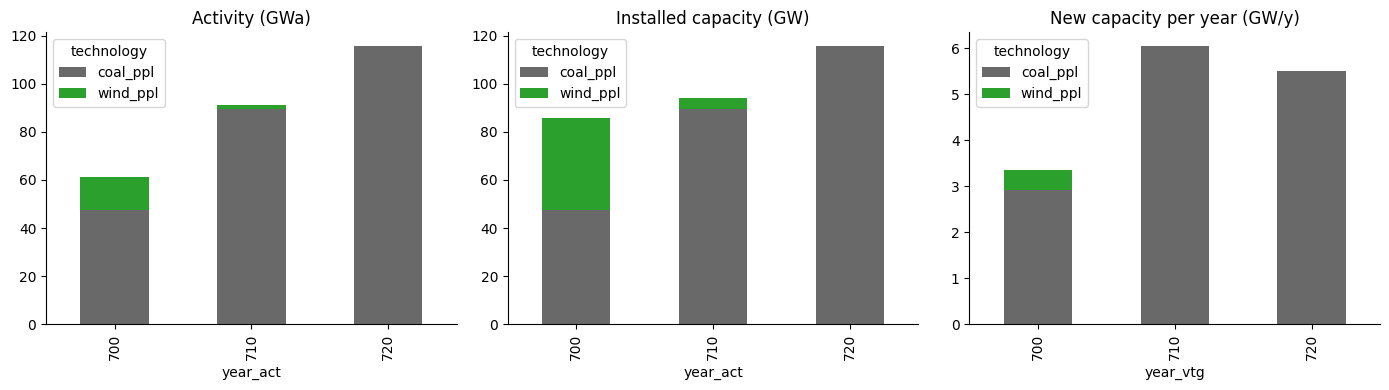

technology,bulb,coal_ppl,grid,wind_ppl
year_act,,,,
700,55.0,47.4,55.0,13.7
710,82.0,89.6,82.0,1.6
720,104.0,115.6,104.0,0.0


In [30]:
act = mi.timeseries(scenario, "ACT")
cap = mi.timeseries(scenario, "CAP")
new = mi.timeseries(scenario, "CAP_NEW")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = {"coal_ppl": "dimgrey", "wind_ppl": "tab:green"}
act[["coal_ppl", "wind_ppl"]].plot.bar(stacked=True, ax=axes[0], color=colors, title="Activity (GWa)")
cap[["coal_ppl", "wind_ppl"]].plot.bar(stacked=True, ax=axes[1], color=colors, title="Installed capacity (GW)")
new[["coal_ppl", "wind_ppl"]].plot.bar(stacked=True, ax=axes[2], color=colors, title="New capacity per year (GW/y)")
plt.tight_layout()
plt.show()
act.round(1)

The existing wind farms keep running in 700 because their investment cost is already paid. All new capacity is coal, and wind disappears once the plants built in 690 reach the end of their lifetime.

The **price of light** is the shadow price of the commodity balance for light (notebook 03, Part 3).

In [31]:
prices = scenario.var("PRICE_COMMODITY")
prices.pivot_table(index="year", columns=["commodity", "level"], values="lvl").round(1)

commodity electricity            light
level           final secondary useful
year                                  
700             506.9     405.6  507.4
710             157.3      91.0  157.8
720             157.3      91.0  157.8

**💬 Question.** The price of light is much higher in period 700 than in 710 and 720. Use the results above (new capacity, lifetimes) to explain why.

*Answer:* *(write the answer here)*

---
# Part 4 · What the solver sees: the MESSAGE equations

`solve()` translates the scenario into a linear programme. The function `mi.build_message()` returns that programme without solving it, so that it can be inspected. The constraint names are those of the [MESSAGEix documentation](https://docs.messageix.org/en/latest/model/MESSAGE/model_core.html):

| Equation | Meaning |
|---|---|
| `COMMODITY_BALANCE` | Output minus input of each commodity at each level must cover demand |
| `CAPACITY_CONSTRAINT` | Activity ≤ capacity factor × installed capacity |
| `CAPACITY_MAINTENANCE` (in `CAP`) | Installed capacity = surviving historical and new capacity |
| `ACTIVITY_CONSTRAINT_UP` | Growth of activity from one period to the next is limited |
| `EMISSION_EQUIVALENCE`, `EMISSION_CONSTRAINT` | Emissions are counted and, if a bound is set, limited |
| `OBJ` | Discounted sum of investment, fixed, variable, and emission-tax costs |

In [32]:
lp = mi.build_message(scenario)
print("decision variables:", lp.nvariables(), "| constraints:", lp.nconstraints())
lp.COMMODITY_BALANCE["light", "useful", 710].pprint()

decision variables: 24 | constraints: 27
{Member of COMMODITY_BALANCE} : Size=9, Index=CL*Y, Active=True
    Key                      : Lower : Body          : Upper : Active
    ('light', 'useful', 710) :  82.0 : ACT[bulb,710] :  +Inf :   True


In [33]:
lp.COMMODITY_BALANCE["electricity", "secondary", 710].pprint()
lp.ACTIVITY_CONSTRAINT_UP["wind_ppl", 710].pprint()

{Member of COMMODITY_BALANCE} : Size=9, Index=CL*Y, Active=True
    Key                               : Lower : Body                                                                     : Upper : Active
    ('electricity', 'secondary', 710) :   0.0 : ACT[coal_ppl,710] + ACT[wind_ppl,710] - 1.1111111111111112*ACT[grid,710] :  +Inf :   True
{Member of ACTIVITY_CONSTRAINT_UP} : Size=6, Index={('coal_ppl', 700), ('coal_ppl', 710), ('coal_ppl', 720), ('wind_ppl', 700), ('wind_ppl', 710), ('wind_ppl', 720)}, Active=True
    Key               : Lower : Body                                                     : Upper : Active
    ('wind_ppl', 710) :  -Inf : ACT[wind_ppl,710] - 2.5937424601000023*ACT[wind_ppl,700] :   0.0 :   True


**💬 Question.** Read the printed constraint for secondary electricity in 710. Which technologies supply it, which technology uses it, and where does the coefficient 1.11 come from?

*Answer:* *(write the answer here)*

---
# Part 5 · Climate policy in Westeros: an emission bound

Following the tutorial *westeros_emissions_bounds*, coal plants emit **7.4 t CO₂ per kWa** of electricity. The emission is declared as `CO2`, which belongs to the emission category `GHG`, and a **cumulative bound** of 500 Mt CO₂ is placed on that category.

In MESSAGEix, a bound with `type_year="cumulative"` limits the **average annual emissions over the model horizon**, weighted by the duration of each period, not the total. A value of 500 therefore means 500 Mt per year on average, or 15,000 Mt over the 30 years.

In [34]:
scen_bd = scenario.clone(scenario="emission_bound")

scen_bd.add_set("emission", "CO2")
scen_bd.add_cat("emission", "GHG", "CO2")

year_df = scen_bd.vintage_and_active_years((country, "coal_ppl"), in_horizon=False)
scen_bd.add_par("emission_factor", make_df(
    "emission_factor", node_loc=country, year_vtg=year_df["year_vtg"], year_act=year_df["year_act"],
    mode="standard", unit="tCO2/kWa", technology="coal_ppl", emission="CO2", value=7.4))

scen_bd.add_par("bound_emission", make_df(
    "bound_emission", node=country, type_emission="GHG", type_tec="all",
    type_year="cumulative", value=500.0, unit="MtCO2"))

scen_bd.solve()
print(f"OBJ: baseline {scenario.var('OBJ'):,.0f} | with bound {scen_bd.var('OBJ'):,.0f} million USD")

OBJ: baseline 154,323 | with bound 187,108 million USD


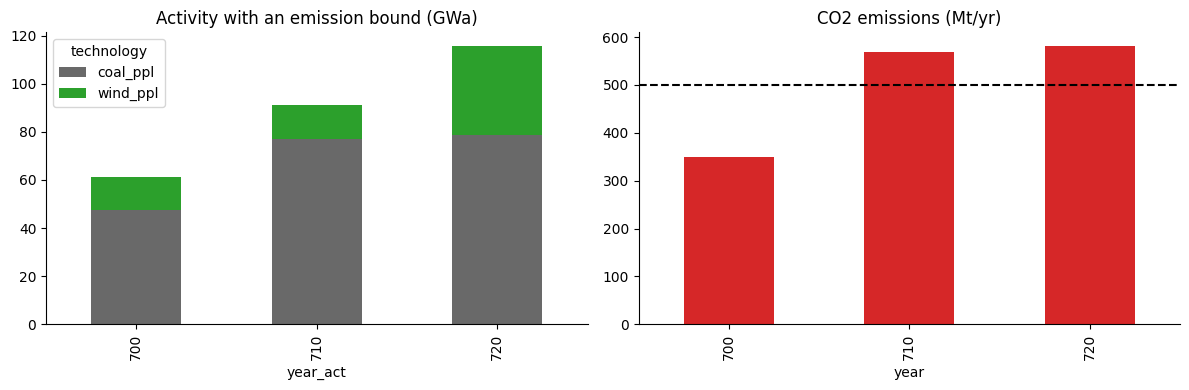

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
mi.timeseries(scen_bd, "ACT")[["coal_ppl", "wind_ppl"]].plot.bar(stacked=True, ax=axes[0], color=colors,
                                                               title="Activity with an emission bound (GWa)")
scen_bd.var("EMISS").set_index("year")["lvl"].plot.bar(ax=axes[1], color="tab:red", title="CO2 emissions (Mt/yr)")
axes[1].axhline(500, color="black", ls="--")
plt.tight_layout()
plt.show()

The bound is met by building wind instead of part of the coal. Emissions are above 500 Mt in the last two periods and below it in the first, so that the duration-weighted average is exactly 500.

The shadow price of the bound is reported as `PRICE_EMISSION`, in USD per tonne of CO₂, for each period.

In [36]:
emission_prices = scen_bd.var("PRICE_EMISSION")
emission_prices

,node,type_emission,year,lvl
0,Westeros,GHG,700,11.67
1,Westeros,GHG,710,19.01
2,Westeros,GHG,720,30.96


### ✏️ Exercise 4: The Hotelling rule

Compute the ratio of the carbon price in each period to the price in the previous period and store it in `ratio`. Compare it with $1.05^{10}$, the growth of a sum of money invested for ten years at the 5% interest rate.

In [37]:
p = emission_prices.set_index("year")["lvl"]
ratio = ___
print(ratio.round(3).to_dict(), "compared with", round(1.05 ** 10, 3))

{'bulb': {700: 55.0, 710: 82.0, 720: 104.0}, 'coal_ppl': {700: 47.4, 710: 89.6, 720: 115.6}, 'grid': {700: 55.0, 710: 82.0, 720: 104.0}, 'wind_ppl': {700: 13.7, 710: 1.6, 720: 0.0}} compared with 1.629


In [38]:
check("the carbon price grows by about 1.05**10 per period", lambda: all(abs(ratio - 1.05 ** 10) < 0.01))

✅ the carbon price grows by about 1.05**10 per period


**💬 Question.** Why does a cumulative emission bound lead to a carbon price that grows at the interest rate?

*Answer:* *(write the answer here)*

---
# Part 6 · Bounds, prices, and taxes

The tutorial *westeros_emissions_taxes* shows that the same outcome can be reached with three different policy instruments. The cumulative bound of Part 5 is the first; the other two are an **annual bound** equal to the emissions of the cumulative-bound scenario, and an **emission tax** equal to its carbon price.

### ✏️ Exercise 5: A carbon tax that reproduces the bound

Clone the baseline into `scen_tax`, add the emission and its factor (copy them from `scen_bd` with `scen_bd.par("emission_factor")`), and add a `tax_emission` with `type_year` equal to each model year and `value` equal to the carbon price of `scen_bd` in that year. Solve it and compare the emissions with those of `scen_bd`.

In [39]:
scen_tax = scenario.clone(scenario="carbon_tax")
scen_tax.add_set("emission", "CO2")
scen_tax.add_cat("emission", "GHG", "CO2")
scen_tax.add_par("emission_factor", scen_bd.par(___))

tax = make_df("tax_emission", node=country, type_emission="GHG", type_tec="all",
              type_year=___, value=___, unit="USD/tCO2")
scen_tax.add_par("tax_emission", tax)
scen_tax.solve()

compare = pd.DataFrame({"bound": scen_bd.var("EMISS").set_index("year")["lvl"],
                        "tax": scen_tax.var("EMISS").set_index("year")["lvl"]})
compare.round(1)

TypeError: unhashable type: 'DataFrame'

In [ ]:
check("the tax scenario keeps average emissions at or below the bound",
      lambda: (compare["tax"] * 10).sum() / 30 <= 500 + 1)

The tax scenario keeps average emissions within the bound, but its emissions in 710 and 720 may be lower than those of the bound scenario. The reason is the knife-edge property of linear models seen in notebook 03: at a tax exactly equal to the shadow price, the planner is indifferent between a range of mixes of coal and wind, and the solver returns one end of that range. Both solutions have the same cost excluding the tax, and both are optimal. The equivalence of a bound and a tax holds for the **marginal** cost of abatement, which is the economically important result.

**💬 Question.** The objective value of `scen_tax` is higher than that of `scen_bd`, even though both scenarios meet the same demand at a similar cost. Where does the difference come from, and does it represent a cost to society?

*Answer:* *(write the answer here)*

---
# Part 7 · Adding a technology

Adding a technology requires the same steps as in Part 2: a set entry, inputs and outputs, lifetime, capacity factor, and costs.

### ✏️ Exercise 6: Solar power in Westeros

Add a technology `solar_ppl` to `scen_bd` (the scenario with the emission bound) and store the result as `scen_solar`. Use: output of secondary electricity, lifetime 20 years, capacity factor 0.25, `inv_cost` 1,000 USD/kW, `fix_cost` 10 USD/kW/yr, and `growth_activity_up` 0.1. Solve and compare the carbon price with that of `scen_bd`.

Running the model with only these parameters gives **no solar at all**. Find out why by reading the growth constraint printed in Part 4, and fix it with the parameter `initial_activity_up` (the activity that a new technology may reach in its first period, here 5 GWa).

<details><summary>Hint</summary>

The growth constraint limits activity in a period to the activity of the previous period multiplied by a growth factor. A technology with no history starts from zero, and zero multiplied by any factor is zero. `initial_activity_up` adds a start-up allowance to that limit.

</details>

In [ ]:
scen_solar = scen_bd.clone(scenario="emission_bound_solar")
tec = "solar_ppl"
scen_solar.add_set("technology", tec)
scen_solar.add_par("technical_lifetime", make_df("technical_lifetime", node_loc=country,
                   year_vtg=history + model_horizon, unit="y", technology=tec, value=20))
year_df = scen_solar.vintage_and_active_years((country, tec), in_horizon=False)
yrs = dict(year_vtg=year_df["year_vtg"], year_act=year_df["year_act"])

scen_solar.add_par("output", make_df("output", node_loc=country, technology=tec, mode="standard", time="year",
                   node_dest=country, time_dest="year", commodity="electricity", level=___, value=1.0,
                   unit="-", **yrs))
scen_solar.add_par("capacity_factor", make_df("capacity_factor", node_loc=country, technology=tec,
                   time="year", value=___, unit="-", **yrs))
scen_solar.add_par("inv_cost", make_df("inv_cost", node_loc=country, technology=tec,
                   year_vtg=model_horizon, value=___, unit="USD/kW"))
scen_solar.add_par("fix_cost", make_df("fix_cost", node_loc=country, technology=tec,
                   value=___, unit="USD/kWa", **yrs))
scen_solar.add_par("growth_activity_up", make_df("growth_activity_up", node_loc=country, technology=tec,
                   year_act=model_horizon, time="year", value=0.1, unit="-"))
scen_solar.add_par(___, make_df(___, node_loc=country, technology=tec,
                   year_act=model_horizon, time="year", value=5, unit="GWa"))
scen_solar.solve()
print(mi.timeseries(scen_solar, "ACT").round(1))
print(scen_solar.var("PRICE_EMISSION").round(2))

In [ ]:
check("solar is used", lambda: mi.timeseries(scen_solar, "ACT")["solar_ppl"].sum() > 0)
check("solar lowers the carbon price",
      lambda: scen_solar.var("PRICE_EMISSION")["lvl"].iloc[0] < scen_bd.var("PRICE_EMISSION")["lvl"].iloc[0])

**💬 Question.** The fix needed in this exercise is a common source of confusion when building MESSAGE models. Explain, with reference to real technologies, why a model needs both a growth rate and a start-up value for new technologies.

*Answer:* *(write the answer here)*

---
# Part 8 · From Westeros to the world

Notebook 05 applies exactly the same formulation to a global energy system. The concepts do not change; the reference energy system becomes larger.

| Westeros | World model (notebook 05) |
|---|---|
| `coal_ppl`, `wind_ppl` | 10 power plant types, including solar, nuclear, hydropower, gas, biomass, and plants with carbon capture and storage (CCS) |
| `grid` (secondary → final electricity) | `elec_t_d` |
| `bulb` (final electricity → light) | 12 end-use technologies, from electric cars to gas boilers and hydrogen |
| One demand (light) | Three demands: specific electricity uses, thermal energy, and transport |
| No fuels | Extraction of coal, gas, oil, and biomass, with fuel costs, and an oil refinery |
| Emission factor on coal_ppl | Emissions from all fossil fuels, and negative emissions from bioenergy with CCS |
| Growth constraints | Growth **and decline** constraints, and a limit on the share of wind and solar |
| Years 700–720 | Years 2030–2100 |

**💬 Final question.** Which assumption in the Westeros model would a policy adviser most need to question before trusting its results, and why?

*Answer:* *(write the answer here)*

---
# References and further reading

- MESSAGEix tutorials: [*westeros_baseline*, *westeros_emissions_bounds*, *westeros_emissions_taxes*](https://github.com/iiasa/message_ix/tree/main/tutorial/westeros). This notebook reproduces their data and steps.
- Huppmann, D., Gidden, M., Fricko, O., Kolp, P., Orthofer, C., Pimmer, M., et al. (2019). The MESSAGEix Integrated Assessment Model and the ix modeling platform (ixmp). *Environmental Modelling & Software*, 112, 143–156. [doi:10.1016/j.envsoft.2018.11.012](https://doi.org/10.1016/j.envsoft.2018.11.012)
- [MESSAGEix documentation: the core model formulation](https://docs.messageix.org/en/latest/model/MESSAGE/model_core.html), including all equations named in Part 4.